In [1]:
# 第一部分：导入必要的库（增强健壮性，可处理缺少 matplotlib 的情况）
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')

# 尝试导入 matplotlib，用于绘图
try:
    import matplotlib.pyplot as plt
    MATPLOTLIB_AVAILABLE = True
except ImportError:
    MATPLOTLIB_AVAILABLE = False
    print("警告: matplotlib 未安装，将无法绘制图表。如需绘图请安装: pip install matplotlib")

# 尝试导入umap（如果可用）
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("umap-learn 未安装。如需使用UMAP降维，请安装: pip install umap-learn")

# 设置中文字体支持（仅在 matplotlib 可用时生效）
if MATPLOTLIB_AVAILABLE:
    plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体显示中文
    plt.rcParams['axes.unicode_minus'] = False    # 解决负号显示异常

[WARNING] ME(7632:16924,MainProcess):2026-10-06-19:51:28.513.000 [mindspore\run_check\_check_version.py:543] The directory C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 does not contain the typical file structure of CUDA
[ERROR] ME(7632:16924,MainProcess):2026-10-06-19:51:28.514.000 [mindspore\run_check\_check_version.py:582] CUDA_PATH C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 is not safe, skip add cuda path.


In [2]:
# 第二部分：可调参数配置区（PCA 降维消融实验）
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1            # 数据采样比例
TEST_SIZE = 0.2                # 测试集比例
PCA_COMPONENTS = 8             # 降维目标维度（与量子比特数一致）
BATCH_SIZE = 32                 # 批处理大小

# 降维方法选择（改为 PCA）
DIM_REDUCTION_METHODS = ['pca']   # 将要运行的降维方法列表
RUN_PCA = True                    # 使用 PCA

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数

# 训练参数
NUM_EPOCHS = 150                 # 训练轮数
LEARNING_RATE = 0.01             # 学习率
PARALLEL_WORKER = 2              # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE        # 运行模式
MS_DEVICE = "CPU"                 # 设备目标
SEED = 42                         # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)

[WARNING] ME(7632:16924,MainProcess):2026-10-06-19:51:36.718.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
# 第三部分：数据加载和处理函数（PCA 降维，与实验一/三/四保持一致）
# ============================================

import os
import numpy as np
from torchvision.datasets import MNIST
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

import mindspore as ms
import mindspore.dataset as ds


def load_mnist_data():
    """加载MNIST数据集（与原始代码相同）"""
    print("正在下载/加载MNIST数据集...")
    data_dir = "./MNIST"
    os.makedirs(data_dir, exist_ok=True)
    
    try:
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    except:
        import tempfile
        temp_dir = tempfile.gettempdir()
        data_dir = os.path.join(temp_dir, "MNIST")
        print(f"使用临时目录: {data_dir}")
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    
    def extract_data(dataset):
        images = dataset.data.numpy().astype(np.float32) / 255.0
        labels = dataset.targets.numpy()
        images_flatten = images.reshape(len(images), -1)
        return images_flatten, labels
    
    train_images, train_labels = extract_data(train_set)
    test_images, test_labels = extract_data(test_set)
    
    # 合并数据并采样
    all_images = np.concatenate([train_images, test_images])
    all_labels = np.concatenate([train_labels, test_labels])
    sampled_indices = np.random.choice(
        len(all_images), 
        int(len(all_images) * SAMPLE_RATIO), 
        replace=False
    )
    sampled_images = all_images[sampled_indices]
    sampled_labels = all_labels[sampled_indices]
    
    print(f"总样本数: {len(all_images)}, 采样后: {len(sampled_images)}")
    print(f"类别分布: {np.unique(sampled_labels, return_counts=True)}")
    
    return sampled_images, sampled_labels


def preprocess_data_pca(images, labels, pca_model=None, scaler=None, is_train=True):
    """
    PCA降维 + 归一化到[-1,1]预处理函数
    （与实验一/三/四保持一致：先 PCA，后 MinMax 到 [-1,1]）
    返回: (dataset, scaler, pca_model)
    """
    if is_train:
        # 训练集：直接对像素做 PCA（图像已经 /255.0 归一化到 [0,1]）
        print("训练 PCA 降维模型...")
        pca_model = PCA(n_components=PCA_COMPONENTS)
        pca_data = pca_model.fit_transform(images)
        explained = pca_model.explained_variance_ratio_.sum()
        print(f"PCA降维完成，输出形状: {pca_data.shape}")
        print(f"累计解释方差比: {explained:.4f}")
        
        # 归一化到 [-1, 1]
        scaler = MinMaxScaler(feature_range=(-1, 1))
        reduced_data = scaler.fit_transform(pca_data)
    else:
        # 测试集：使用训练好的 pca 模型和 scaler
        pca_data = pca_model.transform(images)
        reduced_data = scaler.transform(pca_data)
    
    # 创建MindSpore数据集
    dataset = ds.NumpySlicesDataset(
        data=(reduced_data.astype(np.float32), labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)
    
    return dataset, scaler, pca_model

In [4]:
# 第四部分：量子电路构建函数（消融实验：无Ansatz）
# ============================================

def build_encoder():
    """构建编码器电路（固定，无Ansatz）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder

# ---- 消融实验：Ansatz 构建函数已删除/不调用 ----
# def build_sequential_su4_ansatz(num_layers):
#     ...
# def build_ansatz():
#     ...

def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [5]:
# 第五部分：神经网络定义与训练（消融实验：无Ansatz）
# ============================================

class MQLayerNoAnsatz(nn.Cell):
    """
    自定义量子层（消融实验：无Ansatz参数）
    - 电路中只有编码器，grad_ops 只接受一个 numpy 输入
    - 量子部分无可训练参数，输出对下游全连接层是常量特征
    """
    def __init__(self, expectation_with_grad):
        super(MQLayerNoAnsatz, self).__init__()
        self.expectation_with_grad = expectation_with_grad
        
    def construct(self, x):
        # x: [batch_size, num_encoder_params]（MindSpore Tensor）
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        
        # grad_ops 要求 numpy array 输入
        x_np = x.asnumpy().astype(np.float32)
        out = self.expectation_with_grad(x_np)
        
        # 返回可能是 tuple (expectation, gradient)，取期望值
        if isinstance(out, tuple):
            out = out[0]
        
        # 转回 MindSpore Tensor，供全连接层使用
        out = np.asarray(out).astype(np.float32)
        return ms.Tensor(out, dtype=ms.float32)


class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（仅Z测量，消融实验：无Ansatz）"""
    def __init__(self, quantum_net, num_classes=10):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net
        # 测量维度 = 量子比特数（每个比特一个Z期望值）
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))
        
    def construct(self, x):
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)
        
        quantum_out = self.quantum_net(x)
        logits = self.fc(quantum_out)
        return logits


def train_model(train_dataset, val_dataset, 
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """
    训练模型（消融实验：仅编码层，无Ansatz）
    """
    print(f"\n开始训练: 消融实验 - 仅编码层（无Ansatz）")
    
    # 构建量子电路（仅编码器）
    print("构建量子电路（仅编码器）...")
    encoder = build_encoder()
    full_circuit = encoder  # 只使用编码器，移除 Ansatz
    
    print("量子电路构建完成:")
    print(f"  编码器: {encoder.n_qubits}量子比特")
    print(f"  Ansatz: 已移除（消融实验）")
    
    # 创建哈密顿量和梯度算子（仅Z测量）
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    print(f"  哈密顿量数量: {len(hams)} (单比特Z)")
    
    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )
    
    # 创建量子层（自定义，无Ansatz）和混合网络
    print("创建神经网络...")
    quantum_net = MQLayerNoAnsatz(grad_ops)   # 替换 MQLayer
    net = HybridQuantumNet(quantum_net, num_classes=10)
    
    # 打印可训练参数信息（便于确认量子部分无参数）
    total_params = sum(int(np.prod(p.shape)) for p in net.trainable_params())
    print(f"  可训练参数总数: {total_params}（全部来自全连接层）")
    
    # 损失函数和优化器
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)
    
    # 定义前向传播和梯度函数
    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits
    
    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)
    
    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0
    
    print(f"\n开始训练循环 ({num_epochs} epochs)...")
    
    for epoch in range(num_epochs):
        # 训练
        net.set_train()
        epoch_loss = 0
        step = 0
        
        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1
        
        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)
        
        # 验证
        net.set_train(False)
        correct = 0
        total = 0
        
        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)
        
        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
        
        # 打印进度
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")
    
    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")
    
    return train_losses, val_accuracies, best_val_acc

PCA降维消融实验 - 仅编码层（无Ansatz）

步骤1：加载MNIST数据
正在下载/加载MNIST数据集...
总样本数: 70000, 采样后: 70000
类别分布: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64), array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958],
      dtype=int64))
数据大小: 70000

步骤2：划分训练集和测试集
训练集: 56000 样本, 测试集: 14000 样本

降维方法: pca

步骤3：PCA降维预处理
训练 PCA 降维模型...
PCA降维完成，输出形状: (56000, 8)
累计解释方差比: 0.4384

步骤4：训练量子神经网络（无Ansatz）

开始训练: 消融实验 - 仅编码层（无Ansatz）
构建量子电路（仅编码器）...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 已移除（消融实验）
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  可训练参数总数: 90（全部来自全连接层）

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.6305, 验证准确率=0.5079
Epoch  10/150: 训练损失=1.3034, 验证准确率=0.5311
Epoch  20/150: 训练损失=1.3011, 验证准确率=0.5317
Epoch  30/150: 训练损失=1.3008, 验证准确率=0.5319
Epoch  40/150: 训练损失=1.3007, 验证准确率=0.5318
Epoch  50/150: 训练损失=1.3006, 验证准确率=0.5316
Epoch  60/150: 训练损失=1.3006, 验证准确率=0.5316
Epoch  70/150: 训练损失=1.3006, 验证准确率=0.5317
Epoch  80/150: 训练损失=1.3006, 验证准确率=0.5317
Epoch  90/150: 训练损失=1.3006, 验证准确率=0.5317
Epoch 100/150: 训练损失=

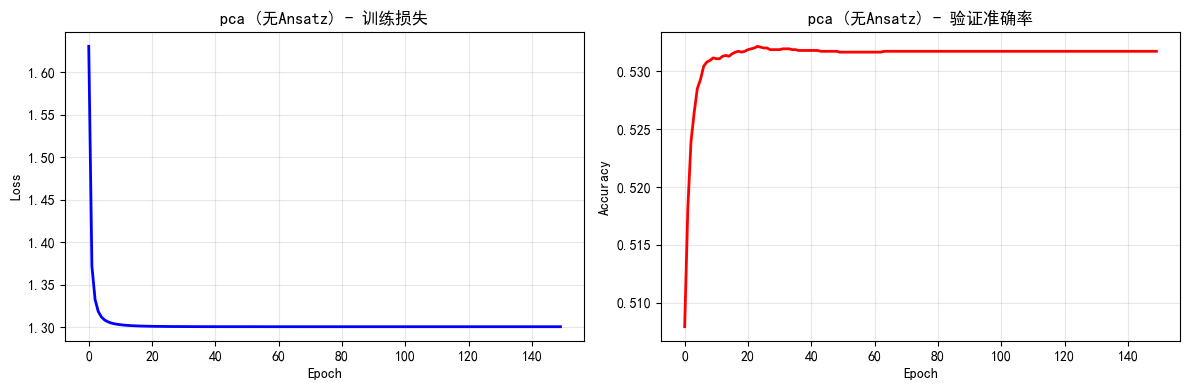


消融实验结果汇总（无Ansatz）
pca (无Ansatz): 最佳验证准确率 = 0.5321

结果已保存到 pca_no_ansatz_results.npz


In [6]:
# 第六部分：主程序 - PCA降维消融实验（无Ansatz）
# ============================================

if __name__ == "__main__":
    print("=" * 60)
    print("PCA降维消融实验 - 仅编码层（无Ansatz）")
    print("=" * 60)

    # 1. 加载数据
    print("\n步骤1：加载MNIST数据")
    all_images, all_labels = load_mnist_data()
    print(f"数据大小: {len(all_images)}")

    # 2. 划分数据集
    print("\n步骤2：划分训练集和测试集")
    train_images, test_images, train_labels, test_labels = train_test_split(
        all_images, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
    )
    print(f"训练集: {len(train_images)} 样本, 测试集: {len(test_images)} 样本")

    # 3. PCA 降维
    all_results = {}

    for method in DIM_REDUCTION_METHODS:
        print(f"\n{'='*60}")
        print(f"降维方法: {method}")
        print(f"{'='*60}")

        if method == 'pca':
            print("\n步骤3：PCA降维预处理")
            train_dataset, scaler, pca_model = preprocess_data_pca(
                train_images, train_labels, is_train=True
            )
            test_dataset, _, _ = preprocess_data_pca(
                test_images, test_labels, scaler=scaler, pca_model=pca_model, is_train=False
            )
        else:
            raise ValueError(f"未知的降维方法: {method}")

        # 4. 训练模型（消融实验）
        print("\n步骤4：训练量子神经网络（无Ansatz）")
        train_losses, val_accuracies, best_val_acc = train_model(
            train_dataset=train_dataset,
            val_dataset=test_dataset,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE
        )

        # 存储结果
        all_results[method] = {
            'train_losses': train_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }

        # 5. 绘制曲线
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, 'b-', linewidth=2)
        plt.title(f'{method} (无Ansatz) - 训练损失')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.grid(True, alpha=0.3)

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, 'r-', linewidth=2)
        plt.title(f'{method} (无Ansatz) - 验证准确率')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # 6. 汇总结果
    print("\n" + "=" * 60)
    print("消融实验结果汇总（无Ansatz）")
    print("=" * 60)
    for method, res in all_results.items():
        print(f"{method} (无Ansatz): 最佳验证准确率 = {res['best_val_acc']:.4f}")

    # 7. 保存结果
    np.savez('pca_no_ansatz_results.npz', 
             train_losses=all_results['pca']['train_losses'],
             val_accuracies=all_results['pca']['val_accuracies'],
             best_val_acc=all_results['pca']['best_val_acc'])
    print("\n结果已保存到 pca_no_ansatz_results.npz")